# 9. A drying droplet

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 3, 5 and 7

A drop of coffee dries on a table and leaves a dark ring: nearly all the coffee ends
up at the edge. Deegan and co-workers (1997) explained why. The edge of the drop is
pinned, so the liquid that evaporates there must be replaced by liquid flowing
outwards from the interior, and the flow carries the dissolved or suspended
material with it. Not every drop leaves a ring, however. Drops whose edge recedes
as they dry leave a mound in the middle, and drops of polymer solutions often leave
something in between, a ring with a raised centre, like a volcano.

Man and Doi (2016) showed that one slow variable, the radius of the drop, is enough
to describe the whole range, and that two numbers decide the pattern: how easily
the contact line moves, and how fast the liquid evaporates compared with how fast
the drop can relax its shape. This chapter derives their model. It is the model
of Chapter 7 with two additions: liquid leaves through the free surface, and the
contact line has a friction of its own.

The check is a numerical solution of the thin-film equation with evaporation, which
carries the solute with the computed flow and leaves it behind where the liquid
dries.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## 9.1 The drop and its variables

The drop is thin and small enough for gravity to be negligible, as in Chapter 7. Its
surface is a spherical cap, which for small slopes is

$$ h(r,t) = H(t)\Big(1 - \frac{r^2}{R(t)^2}\Big) , \qquad V = \frac{\pi}{2}HR^2 , \qquad \theta = \frac{2H}{R} = \frac{4V}{\pi R^3} . \tag{9.1} $$

There are now two quantities that change: the radius $R$ and the volume $V$.
They play different roles.

*The volume is driven from outside.* Liquid evaporates from the surface at a rate
set by the vapour outside the drop: the humidity, the air flow, the temperature. We
take the evaporation rate as given and assume, for simplicity, that the flux $J$
(volume per unit area per unit time) is the same over the whole surface, so that

$$ \dot V = -\pi R^2 J . \tag{9.2} $$

In still air the flux is in fact larger near the edge; Section 9.6 discusses what
this changes. Since $\dot V$ is given, it is not a variable of the Rayleighian.

*The radius is the slow variable.* It is decided by the competition between the
capillary force that pulls the contact angle towards its equilibrium value and the
friction that resists the motion, both as in Chapter 7.

*The solute.* The liquid carries a non-volatile solute (particles or polymer) at a
low concentration $\phi$. It is carried by the flow and does not affect it until the
liquid is gone. Where the solute ends up is the deposit.

## 9.2 The flow inside the drop

Conservation of liquid in the column of radius $r$ now has a loss through the surface:

$$ \frac{\partial h}{\partial t} + \frac1r\frac{\partial}{\partial r}\big(r\,h\,\bar v\big) = -J . $$

With the profile (9.1) the solution is

$$ \bar v(r,t) = r\Big(\frac{\dot R}{R} - \frac{\dot V}{4V}\Big) , \tag{9.3} $$

which the cell below checks. The velocity has two parts. The first is the uniform
stretching of Chapter 7, which moves the liquid with the contact line. The second,
$-r\dot V/4V$, is outwards when the drop evaporates ($\dot V < 0$). It is the flow
that replaces the liquid lost near the edge, where the drop is thin: with a uniform
flux, a thin part of the drop loses a larger fraction of its liquid than a thick
part, and liquid must move outwards to keep the shape a cap.

The two parts cancel when $\dot R/R = \dot V/4V$, that is, when $R \propto V^{1/4}$.
The drop then shrinks with no flow inside it: every element of liquid evaporates
where it is.

In [2]:
r, R, V, Rdot, Vdot, gam, eta, ell, xi_cl, the_e = sp.symbols("r R V Rdot Vdot gamma eta ell xi_cl theta_e", positive=True)
t = sp.symbols("t")
Rt, Vt = sp.Function("R")(t), sp.Function("V")(t)
h = 2 * Vt / (sp.pi * Rt**2) * (1 - r**2 / Rt**2)
J = -sp.diff(Vt, t) / (sp.pi * Rt**2)                                  # Eq. (9.2)
v = r * (sp.diff(Rt, t) / Rt - sp.diff(Vt, t) / (4 * Vt))               # Eq. (9.3)
print("conservation with evaporation:", sp.simplify(sp.diff(h, t) + sp.diff(r * h * v, r) / r + J))

conservation with evaporation: 0


## 9.3 The two functions and the kinetic equation

*Free energy.* As in Eq. (7.2), with $V$ in place of the fixed volume,

$$ A(R, V) = \gamma\Big[\frac{4V^2}{\pi R^4} + \frac{\pi}{2}\theta_e^2R^2\Big] . \tag{9.4} $$

*Dissipation.* There are two sources. The viscous flow in the drop dissipates
$\tfrac12\int(3\eta/h)\,\bar v^2\,dS$, with the same logarithmic divergence at the edge
and the same cut-off as in Section 7.3. With the velocity (9.3) this gives
Eq. (7.6) with $\dot R$ replaced by the relative velocity $\dot R - R\dot V/4V$, which
is the velocity of the liquid at the edge. In addition, the contact line itself
moves over the solid and may have a friction of its own (Section 3.2; Exercise 7.4),
with the constant $\xi_{\rm cl}$ per unit length. It acts on the velocity of the line
relative to the solid, $\dot R$. Together,

$$ \Phi = \frac{3\pi^2\eta\,\ell}{4V}\,R^4\Big(\dot R - \frac{R\dot V}{4V}\Big)^2 + \pi\xi_{\rm cl}R\,\dot R^2 , \qquad \ell = \ln\frac{H}{b} - 1 . \tag{9.5} $$

The line friction describes everything that holds the contact line back besides the
viscous flow: defects of the solid, and the solute that collects at the edge. It is
taken here as a given constant.

*Minimise.* The Rayleighian is $\Phi + (\partial A/\partial R)\dot R + (\partial A/\partial V)\dot V$,
and it is minimised over $\dot R$ only, since $\dot V$ is given. The last term does not
depend on $\dot R$ and drops out. The result is

$$ (1 + k_{\rm cl})\,\dot R = \frac{R\dot V}{4V} + \frac{\gamma}{6\eta\ell}\,\theta\,(\theta^2 - \theta_e^2) , \qquad k_{\rm cl} = \frac{\xi_{\rm cl}\,\theta}{3\eta\ell} , \tag{9.6} $$

the equation of Man and Doi (2016). The number $k_{\rm cl}$ compares the friction of the
contact line with the viscous friction of the wedge of liquid behind it,
$\xi_{\rm hyd} = 3\eta\ell/\theta$ of Eq. (7.7). The cell below derives Eq. (9.6).

In [3]:
A = gam * (4 * V**2 / (sp.pi * R**4) + sp.pi * the_e**2 * R**2 / 2)
Phi = 3 * sp.pi**2 * eta * ell * R**4 / (4 * V) * (Rdot - R * Vdot / (4 * V)) ** 2 + sp.pi * xi_cl * R * Rdot**2
rayleighian = Phi + sp.diff(A, R) * Rdot + sp.diff(A, V) * Vdot
Rdot_min = sp.solve(sp.diff(rayleighian, Rdot), Rdot)[0]
theta = 4 * V / (sp.pi * R**3)
k_cl = xi_cl * theta / (3 * eta * ell)
target = (R * Vdot / (4 * V) + gam * theta * (theta**2 - the_e**2) / (6 * eta * ell)) / (1 + k_cl)
print("difference from Eq. (9.6):", sp.simplify(Rdot_min - target))

difference from Eq. (9.6): 0


The two terms on the right of Eq. (9.6) are the two things that move the edge.
Evaporation alone would shrink the drop as $V^{1/4}$, without internal flow. The
capillary force pulls the angle towards $\theta_e$. Line friction divides both by
$1 + k_{\rm cl}$: it slows the edge, and a slow edge on an evaporating drop means an
outward flow, by Eq. (9.3).

*Two time scales.* Evaporation empties the drop in a time of order
$\tau_{\rm ev} = V_0/\pi R_0^2J$. The capillary force restores the angle in a time of
order $\tau_{\rm re} = \eta R_0/\gamma\theta_e^3$ (Exercise 7.2, without the logarithm).
Their ratio

$$ k_{\rm ev} = \frac{\tau_{\rm re}}{\tau_{\rm ev}} \tag{9.7} $$

is the second number of the problem. For a water drop of 1 mm with $\theta_e = 0.2$,
$\tau_{\rm re} \approx 2$ ms and $\tau_{\rm ev}$ is minutes, so $k_{\rm ev} \sim 10^{-5}$:
water relaxes almost instantly. A concentrated polymer solution with a viscosity of
10 Pa s has $\tau_{\rm re} \approx 20$ s and can reach $k_{\rm ev} \sim 0.1$.

*Units.* From here on, lengths are in units of $R_0$, volumes of $V_0$ and times of
$\tau_{\rm ev}$; the drop starts at equilibrium, $\theta_0 = \theta_e$; $J$ is constant;
the cut-off is $b = 10^{-5}H_0$; and $k_{\rm cl}$ is treated as a constant, as in the
work of Man and Doi (Exercise 4 lets $\xi_{\rm cl}$ be the constant instead). In these
units Eqs. (9.2) and (9.6) become

$$ \dot V = -R^2 , \qquad (1 + k_{\rm cl})\,\dot R = \frac{R\dot V}{4V} + \frac{q\,(q^2 - 1)}{6\,\ell\,k_{\rm ev}} , \qquad q = \frac{\theta}{\theta_e} = \frac{V}{R^3} . \tag{9.8} $$

The integration stops when the drop is ten times thicker than the cut-off, $H = 10b$;
the thin film that is left dries where it is.

In [4]:
LOG_H0_OVER_B = math.log(1e5)

def drying(k_cl, k_ev, n_t=12000):
    """Eq. (9.8), with W = integral of (Rdot/R - Vdot/4V) dt for the paths of the solute."""
    def rhs(t, y):
        R, V = y[0], y[1]
        Vdot = -R**2
        capillary = 0.0
        if np.isfinite(k_ev):
            q = V / R**3
            ell = LOG_H0_OVER_B + math.log(V / R**2) - 1          # ln(H/b) - 1, H/H0 = V/R^2
            capillary = q * (q * q - 1) / (6 * ell * k_ev)
        Rdot = (R * Vdot / (4 * V) + capillary) / (1 + k_cl)
        return [Rdot, Vdot, Rdot / R - Vdot / (4 * V)]
    thin = lambda t, y: y[1] / y[0] ** 2 - 10 * math.exp(-LOG_H0_OVER_B)
    thin.terminal = True
    sol = solve_ivp(rhs, (0, 50), [1.0, 1.0, 0.0], events=thin, dense_output=True, rtol=1e-11, atol=1e-14, method="LSODA")
    T = sol.t[-1]
    t = np.concatenate((np.linspace(0, 0.99 * T, n_t // 2), T * (1 - np.logspace(-2, -10, n_t // 2))))
    R, V, W = sol.sol(t)
    return dict(t=t, R=R, V=V, W=W)

slow, fast = 1e-3, 1.0
for k_ev in (fast, slow):
    for k in (0.0, 1.0, 10.0):
        run = drying(k, k_ev)
        half = np.argmin(np.abs(run["V"] - 0.5))
        print(f"k_ev = {k_ev:5.3f}, k_cl = {k:4.1f}:  when half the liquid is gone, R = {run['R'][half]:.3f},"
              f" theta/theta_e = {run['V'][half] / run['R'][half] ** 3:.3f};  at the end R = {run['R'][-1]:.3f}")

k_ev = 1.000, k_cl =  0.0:  when half the liquid is gone, R = 0.840, theta/theta_e = 0.844;  at the end R = 0.010
k_ev = 1.000, k_cl =  1.0:  when half the liquid is gone, R = 0.916, theta/theta_e = 0.651;  at the end R = 0.214
k_ev = 1.000, k_cl = 10.0:  when half the liquid is gone, R = 0.984, theta/theta_e = 0.525;  at the end R = 0.803


k_ev = 0.001, k_cl =  0.0:  when half the liquid is gone, R = 0.794, theta/theta_e = 0.997;  at the end R = 0.000
k_ev = 0.001, k_cl =  1.0:  when half the liquid is gone, R = 0.797, theta/theta_e = 0.987;  at the end R = 0.000


k_ev = 0.001, k_cl = 10.0:  when half the liquid is gone, R = 0.837, theta/theta_e = 0.852;  at the end R = 0.000


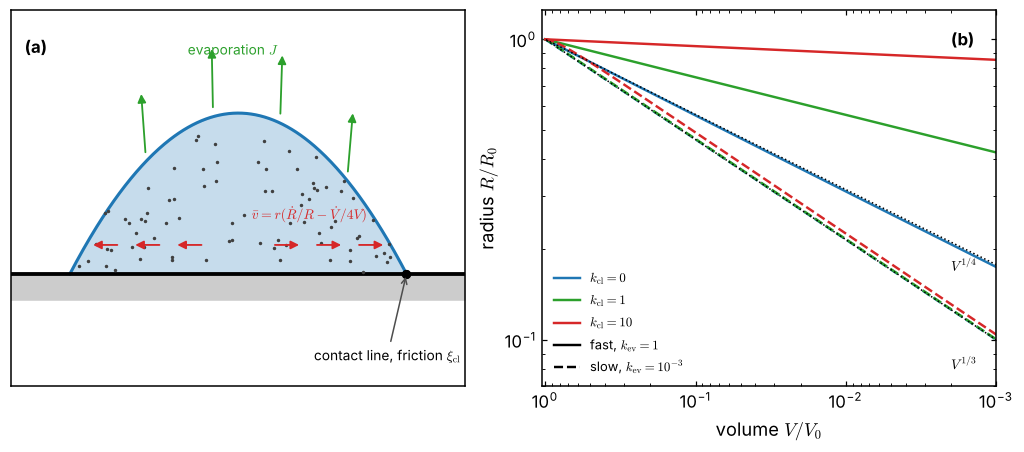

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 4.0))

# (a) schematic
x = np.linspace(-1, 1, 300)
ax1.fill_between(x, 0, 0.5 * (1 - x**2), color="C0", alpha=0.25)
ax1.plot(x, 0.5 * (1 - x**2), "C0", lw=2)
ax1.plot([-1.35, 1.35], [0, 0], "k", lw=2.5); ax1.fill_between([-1.35, 1.35], -0.08, 0, color="0.8")
for x0 in (-0.55, -0.15, 0.25, 0.65):
    y0 = 0.5 * (1 - x0**2)
    ax1.annotate("", xy=(x0 * 1.05, y0 + 0.22), xytext=(x0, y0 + 0.02), arrowprops=dict(arrowstyle="-|>", color="C2", lw=1.2))
ax1.text(-0.3, 0.68, "evaporation $J$", color="C2", fontsize=9)
for x0 in (0.2, 0.45, 0.7):
    for s in (1, -1):
        ax1.annotate("", xy=(s * (x0 + 0.18), 0.09), xytext=(s * x0, 0.09), arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.2))
ax1.text(0.08, 0.17, r"$\bar v = r(\dot R/R - \dot V/4V)$", color="C3", fontsize=9)
rng = np.random.default_rng(3)
px = rng.uniform(-0.95, 0.95, 80); py = rng.uniform(0, 1, 80) * 0.5 * (1 - px**2)
ax1.plot(px, py, ".", color="0.25", ms=2.5)
ax1.plot([1, 1], [0, 0], "ko", ms=5)
ax1.annotate(r"contact line, friction $\xi_{\rm cl}$", xy=(1.0, 0.0), xytext=(0.45, -0.27), fontsize=9,
             arrowprops=dict(arrowstyle="->", color="0.3"))
ax1.set_xlim(-1.35, 1.35); ax1.set_ylim(-0.35, 0.82); ax1.set_xticks([]); ax1.set_yticks([])
on.panel_label(ax1, "(a)", x=0.03, y=0.93)

# (b) radius against volume
for k, color in ((0.0, "C0"), (1.0, "C2"), (10.0, "C3")):
    for k_ev, style in ((fast, "-"), (slow, "--")):
        run = drying(k, k_ev)
        ax2.loglog(run["V"], run["R"], style, color=color, lw=1.6,
                   label=rf"$k_{{\rm cl}} = {k:g}$" if style == "-" else None)
VV = np.logspace(-3, 0, 20)
ax2.loglog(VV, VV ** 0.25, "k:", lw=1); ax2.text(2e-3, 0.17, r"$V^{1/4}$", fontsize=9)
ax2.loglog(VV, VV ** (1 / 3), "k:", lw=1); ax2.text(2e-3, 0.08, r"$V^{1/3}$", fontsize=9)
ax2.plot([], [], "k-", label=r"fast, $k_{\rm ev} = 1$"); ax2.plot([], [], "k--", label=r"slow, $k_{\rm ev} = 10^{-3}$")
ax2.set_xlabel("volume $V/V_0$"); ax2.set_ylabel("radius $R/R_0$")
ax2.set_xlim(1e-3, 1.05); ax2.set_ylim(0.07, 1.25)
ax2.invert_xaxis()
ax2.legend(loc="lower left", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.9, y=0.95)
plt.show()

**Figure 9.1.** **(a)** The drying drop. Liquid evaporates with a uniform flux from
the surface; the flow inside (red) carries the solute (grey dots) outwards when the
contact line lags behind. **(b)** Radius against the volume left, as the drop dries
(from right to left). With slow evaporation (dashed) the drop keeps close to its
equilibrium angle and $R \propto V^{1/3}$, unless the line friction is strong. With fast evaporation
(full lines) the angle falls; without line friction $R \propto V^{1/4}$, and with
strong line friction the edge stays almost pinned.

## 9.4 Where the solute goes

An element of solute moves with the liquid. By Eq. (9.3) its distance $\tilde r$ from
the axis obeys

$$ \dot{\tilde r} = \Big(\frac{\dot R}{R} - \frac{\dot V}{4V}\Big)\tilde r . \tag{9.9} $$

All elements move in proportion, so the solute that started at $r_0$ is at
$\tilde r = r_0\,e^{W(t)}$, with $W = \int(\dot R/R - \dot V/4V)\,dt$ the same for all of
them. It stays on the solid where the receding contact line reaches it, $\tilde r = R$.
Since the solute between $r_0$ and $r_0 + dr_0$ ends up between $r$ and $r + dr$, the
amount deposited per unit area is

$$ \mu(r) = \phi_0 H_0\Big(1 - \frac{r_0^2}{R_0^2}\Big)\frac{r_0}{r}\frac{dr_0}{dr} . \tag{9.10} $$

*Fast evaporation.* When $k_{\rm ev}$ is large the capillary term of Eq. (9.6) is
negligible, $\dot R = R\dot V/4V(1 + k_{\rm cl})$, and Eq. (9.9) becomes
$\dot{\tilde r}/\tilde r = -k_{\rm cl}\,\dot R/R$. Then $\tilde r\,R^{k_{\rm cl}}$ is constant,
the element is caught when $R = r_0^{1/(1 + k_{\rm cl})}$ (in units of $R_0$), and

$$ \mu(r) = \phi_0H_0\,(1 + k_{\rm cl})\,r^{2k_{\rm cl}}\big[1 - r^{2(1 + k_{\rm cl})}\big] , \qquad r_p = \Big(\frac{k_{\rm cl}}{2k_{\rm cl} + 1}\Big)^{1/2(1 + k_{\rm cl})} \tag{9.11} $$

(Man and Doi, 2016). The deposit has its peak at $r_p$. Without line friction the
solute does not move at all ($\dot{\tilde r} = 0$), and the deposit has the shape of the
drop, a mountain. As $k_{\rm cl}$ grows the peak moves out, through a volcano, to a ring
at the edge. Remarkably, this limit does not depend on how fast or how the volume
decreases.

*Slow evaporation.* When $k_{\rm ev}$ is small the angle stays at $\theta_e$, $R \propto V^{1/3}$
for any line friction, and the flow is inwards; the deposit is a mountain
(Exercise 3).

The cell below computes the deposit from Eqs. (9.8)–(9.10) for any $k_{\rm cl}$ and
$k_{\rm ev}$, and compares it with Eq. (9.11).

In [6]:
def deposit(run, n=4000):
    """Final positions of n solute elements and the deposit density, Eq. (9.10)."""
    t, R, W = run["t"], run["R"], run["W"]
    r0 = (np.arange(n) + 0.5) / n
    reach = R * np.exp(-W)                     # elements that started beyond this have been caught
    caught = r0 > reach[-1]
    order = np.argsort(reach)
    rf = r0 * np.exp(W[-1])                    # elements still in the thin film dry where they are
    rf[caught] = np.interp(np.interp(r0[caught], reach[order], t[order]), t, R)
    mu = (1 - r0**2) * r0 / (rf * np.gradient(rf, r0))
    deposit.caught = caught                    # kept for the check below
    return r0, rf, mu

def deposit_fast(r, k):
    return (1 + k) * r ** (2 * k) * (1 - r ** (2 * (1 + k)))

def peak_fast(k):
    return (k / (2 * k + 1)) ** (1 / (2 * (1 + k)))

very_fast = drying(2.0, np.inf)
r0, rf, mu = deposit(very_fast)
c = deposit.caught & np.roll(deposit.caught, 5) & (r0 < 0.99)       # away from the edge of the caught range
print(f"k_ev -> infinity, k_cl = 2, solute caught by the contact line ({100 * np.mean(deposit.caught):.0f} % of the elements):")
print(f"   final radius vs r0^(1/3): largest difference {np.max(np.abs(rf[c] - r0[c] ** (1 / 3))):.1e};"
      f"  deposit vs Eq. (9.11): {np.max(np.abs(mu[c] - deposit_fast(rf[c], 2.0))) / deposit_fast(rf, 2.0).max():.1e}")
print(f"solute in the deposit: {np.trapezoid(2 * np.pi * rf * mu, rf):.5f}   (pi/2 = {math.pi / 2:.5f})")

k_values = np.concatenate(([0.0], np.logspace(-2, 2, 25)))
peaks = {}
for k_ev in (np.inf, 1.0, 0.1, 0.01, 1e-3):
    peaks[k_ev] = []
    for k in k_values:
        r0, rf, mu = deposit(drying(k, k_ev))
        peaks[k_ev].append(rf[np.argmax(mu)])
    peaks[k_ev] = np.array(peaks[k_ev])
print("\npeak position r_p/R0 for k_cl =      0     0.1    0.32     1     3.2     10    100")
idx = [0] + [int(np.argmin(np.abs(k_values - k))) for k in (0.1, 0.316, 1, 3.16, 10, 100)]
print("  Eq. (9.11)                   " + " ".join(f"{peak_fast(k_values[i]):6.3f}" for i in idx))
for k_ev, p in peaks.items():
    print(f"  k_ev = {k_ev:6}               " + " ".join(f"{p[i]:6.3f}" for i in idx))

k_ev -> infinity, k_cl = 2, solute caught by the contact line (94 % of the elements):
   final radius vs r0^(1/3): largest difference 4.1e-07;  deposit vs Eq. (9.11): 4.3e-04
solute in the deposit: 1.57080   (pi/2 = 1.57080)



peak position r_p/R0 for k_cl =      0     0.1    0.32     1     3.2     10    100
  Eq. (9.11)                    0.000  0.323  0.536  0.760  0.904  0.967  0.997
  k_ev =    inf                0.000  0.323  0.536  0.760  0.904  0.967  0.997
  k_ev =    1.0                0.000  0.309  0.527  0.755  0.902  0.966  0.996
  k_ev =    0.1                0.000  0.176  0.430  0.707  0.884  0.960  0.996
  k_ev =   0.01                0.000  0.000  0.000  0.000  0.711  0.909  0.991
  k_ev =  0.001                0.000  0.000  0.000  0.000  0.000  0.000  0.947


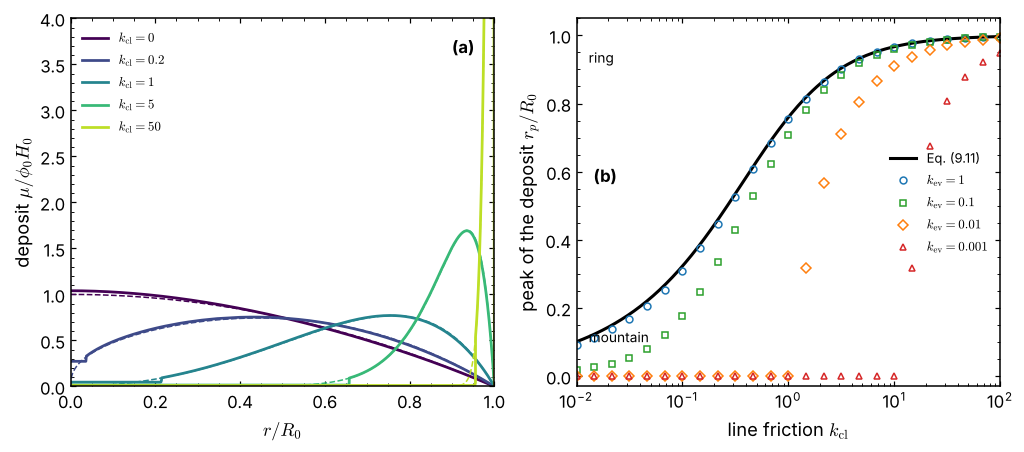

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 4.0))
rr = np.linspace(0, 1, 400)
for k, color in zip((0.0, 0.2, 1.0, 5.0, 50.0), plt.cm.viridis(np.linspace(0, 0.9, 5))):
    r0, rf, mu = deposit(drying(k, fast))
    ax1.plot(rf, mu, color=color, lw=1.8, label=rf"$k_{{\rm cl}} = {k:g}$")
    ax1.plot(rr, deposit_fast(rr, k), "--", color=color, lw=1)
ax1.set_xlabel("$r/R_0$"); ax1.set_ylabel(r"deposit $\mu/\phi_0H_0$")
ax1.set_xlim(0, 1.0); ax1.set_ylim(0, 4)
ax1.legend(loc="upper left", fontsize=8.5); on.panel_label(ax1, "(a)", x=0.9, y=0.95)

kk = np.logspace(-2, 2, 200)
ax2.semilogx(kk, peak_fast(kk), "k-", lw=2, label="Eq. (9.11)")
for (k_ev, p), marker, color in zip(list(peaks.items())[1:], "osD^", ("C0", "C2", "C1", "C3")):
    ax2.semilogx(k_values[1:], p[1:], marker, color=color, mfc="none", ms=4.5, label=rf"$k_{{\rm ev}} = {k_ev:g}$")
ax2.set_xlabel(r"line friction $k_{\rm cl}$"); ax2.set_ylabel("peak of the deposit $r_p/R_0$")
ax2.set_xlim(1e-2, 1e2); ax2.set_ylim(-0.03, 1.05)
ax2.text(0.013, 0.92, "ring", fontsize=9); ax2.text(0.013, 0.1, "mountain", fontsize=9)
ax2.legend(loc="center right", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.04, y=0.6)
plt.show()

**Figure 9.2.** **(a)** The deposit for fast evaporation ($k_{\rm ev} = 1$, full lines)
and in the limit $k_{\rm ev} \to \infty$, Eq. (9.11) (dashed). Without line friction the
deposit has the shape of the drop; with increasing friction it becomes a volcano
and then a ring (for $k_{\rm cl} = 50$ it rises off the scale). The flat part near the
centre is the solute in the last thin film, which dries where it is. **(b)** Position of the peak against the line friction. For
$k_{\rm ev} \gtrsim 1$ it follows Eq. (9.11); for slower evaporation the capillary
force keeps the edge moving, and a ring forms only at a larger line friction.

## 9.5 Check: the thin-film equation with evaporation

The model rests on the cap shape (9.1) at all times, on the cut-off at the edge, and
on the assumption that the solute moves with the depth-averaged velocity of a cap.
The thin-film equation of Section 7.5, with a loss term for evaporation, makes none
of these assumptions about the shape:

$$ \frac{\partial h}{\partial t} = -\frac{\gamma}{3\eta}\,\nabla\cdot\big(h^3\,\nabla p\big) - J , \qquad \frac{\partial s}{\partial t} = -\nabla\cdot\Big(\frac{s}{h}\,\mathbf q\Big) , \tag{9.12} $$

where $s = \phi h$ is the solute per unit area and $\mathbf q$ the liquid flux. The function
`on.drying_film_fv` solves it on a precursor film, with the disjoining pressure of
Section 7.5 for partial wetting; the precursor film neither flows nor evaporates,
so the solute left in it is the deposit.

What the thin-film equation cannot represent is a friction of the contact line
separate from the viscous friction: in it, the line moves only by the flow. The
comparison is therefore for $k_{\rm cl} = 0$, with evaporation from slow to fast.
Line friction is checked only through the limit (9.11), which Figure 9.2 confirms.

*Units* are those of Section 7.5: lengths in $R_0$, thicknesses in $H_0$, times in
$3\eta R_0^4/\gamma H_0^3$. The drop starts at equilibrium with $\theta_e = 2H_0/R_0$, the
precursor film is $b = 0.005\,H_0$, and both calculations stop when 3 % of the liquid
is left. In these units $\tau_{\rm re} = 1/24$ and $\tau_{\rm ev} = 1/2J$, so
$k_{\rm ev} = J/12$.

In [8]:
B_FILM, THETA_E = 0.005, 2.0
edges = np.linspace(0.0, 1.6, 801)
r_c = 0.5 * (edges[1:] + edges[:-1])
cap = np.maximum(1 - r_c**2, 0.0)

def cap_model(J, k_cl=0.0, n_t=4000):
    """Eq. (9.6) in the thin-film units: (1 + k) Rdot = R Vdot/4V + theta (theta^2 - theta_e^2) / 2 ell."""
    def rhs(t, y):
        R, V = y[0], y[1]
        theta, H = 4 * V / (math.pi * R**3), 2 * V / (math.pi * R**2)
        ell = math.log(H / B_FILM) - 1
        Vdot = -J * math.pi * R**2
        Rdot = (R * Vdot / (4 * V) + theta * (theta**2 - THETA_E**2) / (2 * ell)) / (1 + k_cl)
        return [Rdot, Vdot, Rdot / R - Vdot / (4 * V)]
    stop = lambda t, y: y[1] - 0.03 * math.pi / 2
    stop.terminal = True
    sol = solve_ivp(rhs, (0, 1e4), [1.0, math.pi / 2, 0.0], events=stop, dense_output=True, rtol=1e-11, atol=1e-13)
    t = np.linspace(0, sol.t[-1], n_t)
    R, V, W = sol.sol(t)
    return dict(t=t, R=R, V=V, W=W)

checks = {}
for J in (0.02, 0.5, 5.0):
    film = on.drying_film_fv(cap + B_FILM, cap, edges, evaporation=J, theta_e=THETA_E, b=B_FILM, stop_volume=0.03, n_out=120)
    film["R"] = np.array([on.fit_cap(r_c, h, b=B_FILM)[1] for h in film["h"]])
    model = cap_model(J)
    checks[J] = (film, model)
    gap = np.max(np.abs(np.interp(film["t"], model["t"], model["R"]) - film["R"]))
    print(f"J = {J:4} (k_ev = {J / 12:.4f}): drying time {film['t'][-1]:.4f} (thin film), {model['t'][-1]:.4f} (Eq. 9.6);"
          f"  largest difference in R: {gap:.4f};  solute drift {np.ptp(film['solute']):.1e}")

def cumulative(r, density, at):
    """Fraction of the solute deposited within the radius `at`."""
    order = np.argsort(r)
    c = np.concatenate(([0.0], np.cumsum(0.5 * (density[order][1:] * r[order][1:] + density[order][:-1] * r[order][:-1]) * np.diff(r[order]))))
    return np.interp(at, r[order], 2 * math.pi * c) / (math.pi / 2)

radii = np.array([0.2, 0.4, 0.6, 0.8, 1.0])
print("\nfraction of the solute deposited within r =   " + "   ".join(f"{x:.1f}" for x in radii))
for J, (film, model) in checks.items():
    r0, rf, mu = deposit(model)
    print(f"  J = {J:4}   thin film                      " + "  ".join(f"{v:.3f}" for v in cumulative(r_c, film["s"][-1], radii)))
    print("            Eq. (9.6) with Eq. (9.10)      " + "  ".join(f"{v:.3f}" for v in cumulative(rf, mu, radii)))

J = 0.02 (k_ev = 0.0017): drying time 51.0811 (thin film), 51.6408 (Eq. 9.6);  largest difference in R: 0.0055;  solute drift 2.2e-16


J =  0.5 (k_ev = 0.0417): drying time 2.0070 (thin film), 2.0120 (Eq. 9.6);  largest difference in R: 0.0060;  solute drift 2.2e-16


J =  5.0 (k_ev = 0.4167): drying time 0.1749 (thin film), 0.1738 (Eq. 9.6);  largest difference in R: 0.0373;  solute drift 2.2e-16

fraction of the solute deposited within r =   0.2   0.4   0.6   0.8   1.0
  J = 0.02   thin film                      0.132  0.408  0.681  0.900  0.999
            Eq. (9.6) with Eq. (9.10)      0.138  0.442  0.713  0.919  1.000
  J =  0.5   thin film                      0.131  0.425  0.694  0.903  1.000
            Eq. (9.6) with Eq. (9.10)      0.135  0.434  0.702  0.909  1.000
  J =  5.0   thin film                      0.087  0.339  0.628  0.881  1.000
            Eq. (9.6) with Eq. (9.10)      0.093  0.342  0.626  0.880  1.000


The two descriptions agree. For slow and moderate evaporation the radius from
Eq. (9.6) stays within $0.006\,R_0$ of the thin-film radius during the whole drying,
and the drying times agree to 1 %. For the fastest drop the difference grows to
$0.04\,R_0$ near the end, when the drop is thin and its angle has fallen well below
$\theta_e$: the cap shape is then less accurate near the edge, as in Section 7.6. The
deposits agree as well: the fraction of the solute that lies within a given radius
differs by at most 0.03, and the solute is conserved to rounding error in both.

Without line friction every deposit here is mountain-like: the solute moves slightly
inwards or not at all. The thin-film equation, which knows nothing about trial shapes,
confirms the first half of Man and Doi's picture. The second half, the ring made by
a held contact line, rests on the friction $\xi_{\rm cl}$, which has to be measured.

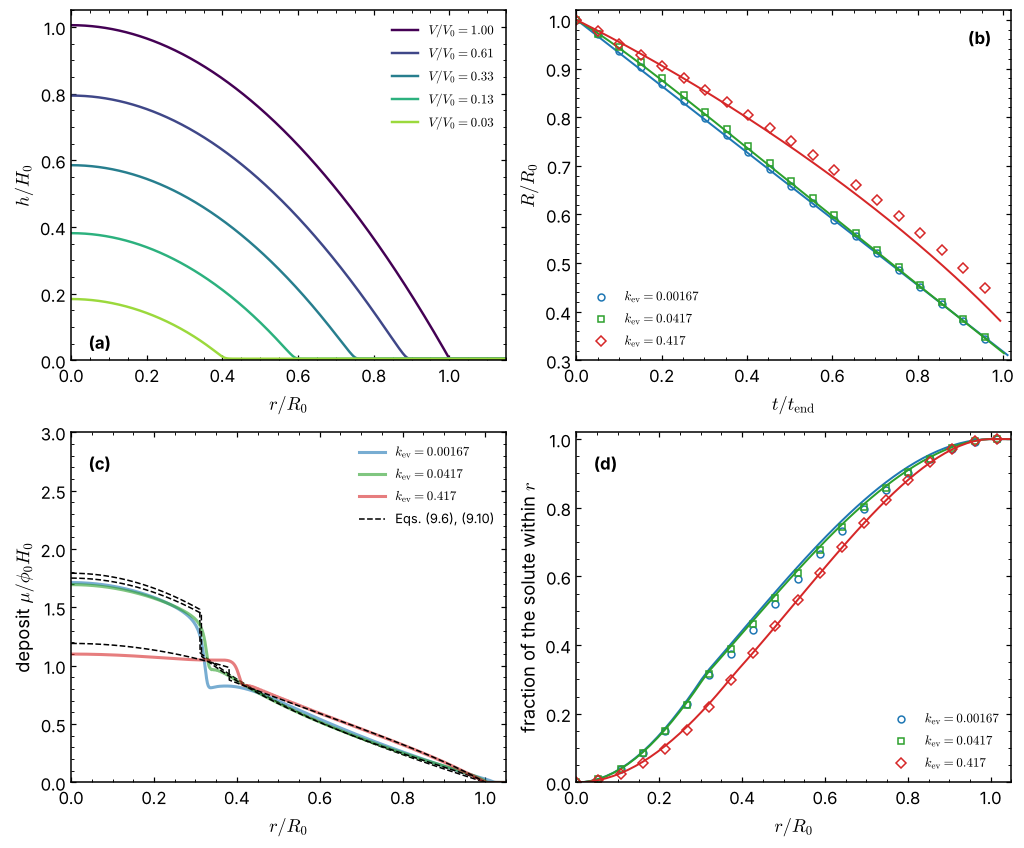

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))
film, model = checks[5.0]

ax = axes[0, 0]
for k, color in zip((0, 30, 60, 90, 119), plt.cm.viridis(np.linspace(0, 0.85, 5))):
    ax.plot(r_c, film["h"][k], color=color, label=rf"$V/V_0 = {film['volume'][k] / film['volume'][0]:.2f}$")
ax.set_xlabel("$r/R_0$"); ax.set_ylabel("$h/H_0$"); ax.set_xlim(0, 1.15); ax.set_ylim(0, 1.05)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(a)", x=0.04, y=0.08)

ax = axes[0, 1]
for (J, (film_J, model_J)), color, marker in zip(checks.items(), ("C0", "C2", "C3"), "osD"):
    T = film_J["t"][-1]
    ax.plot(film_J["t"][::6] / T, film_J["R"][::6], marker, color=color, mfc="none", ms=4.5, label=rf"$k_{{\rm ev}} = {J / 12:.3g}$")
    ax.plot(model_J["t"] / T, model_J["R"], "-", color=color, lw=1.3)
ax.set_xlabel(r"$t/t_{\rm end}$"); ax.set_ylabel("$R/R_0$"); ax.set_xlim(0, 1.02); ax.set_ylim(0.3, 1.02)
ax.legend(loc="lower left", fontsize=8.5); on.panel_label(ax, "(b)", x=0.9, y=0.95)

ax = axes[1, 0]
for (J, (film_J, model_J)), color in zip(checks.items(), ("C0", "C2", "C3")):
    r0, rf, mu = deposit(model_J)
    ax.plot(r_c, film_J["s"][-1], color=color, lw=2, alpha=0.6, label=rf"$k_{{\rm ev}} = {J / 12:.3g}$")
    ax.plot(rf, mu, "k--", lw=1)
ax.plot([], [], "k--", lw=1, label="Eqs. (9.6), (9.10)")
ax.set_xlabel("$r/R_0$"); ax.set_ylabel(r"deposit $\mu/\phi_0H_0$"); ax.set_xlim(0, 1.05); ax.set_ylim(0, 3)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(c)", x=0.04, y=0.94)

ax = axes[1, 1]
rr = np.linspace(0, 1.05, 60)
for (J, (film_J, model_J)), color, marker in zip(checks.items(), ("C0", "C2", "C3"), "osD"):
    r0, rf, mu = deposit(model_J)
    ax.plot(rr[::3], cumulative(r_c, film_J["s"][-1], rr[::3]), marker, color=color, mfc="none", ms=4.5, label=rf"$k_{{\rm ev}} = {J / 12:.3g}$")
    ax.plot(rr, cumulative(rf, mu, rr), "-", color=color, lw=1.3)
ax.set_xlabel("$r/R_0$"); ax.set_ylabel("fraction of the solute within $r$"); ax.set_xlim(0, 1.05); ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=8.5); on.panel_label(ax, "(d)", x=0.04, y=0.94)
plt.show()

**Figure 9.3.** Check against the thin-film equation with evaporation, without line
friction. **(a)** Profiles of the fastest-drying drop ($k_{\rm ev} = 0.42$): it stays
close to a cap while it shrinks and flattens. **(b)** Radius against time, scaled by
the drying time: thin-film equation (symbols) and Eq. (9.6) (lines). **(c)** The
deposit left at the end; the dashed lines are Eqs. (9.6) and (9.10). The raised
central part is the solute in the last 3 % of the liquid, which dries in place. **(d)** The same
deposits as the fraction of the solute that lies within the radius $r$.

## 9.6 What to trust

The model captures the main fact, which the thin-film check confirms quantitatively
for a mobile contact line: the deposit is decided by how the edge moves compared
with how the liquid is lost. A receding edge leaves a mountain; a held edge, a ring;
in between, a volcano. The two numbers $k_{\rm cl}$ and $k_{\rm ev}$ organise the patterns,
and the peak position (9.11) is a simple, testable prediction.

Three simplifications limit the numbers:

* *The evaporation flux.* In still air, evaporation is limited by the diffusion of
  vapour, and the flux grows without bound towards the edge of the drop (Deegan and
  co-workers, 1997). This strengthens the outward flow and favours rings; with a
  pinned edge it gives a ring even with a uniform shape of the drop. The model with
  a uniform flux underestimates ring formation.
* *The line friction* is a parameter, not a prediction. In practice it depends on
  the solute that accumulates at the edge, which can pin the line by itself, and it
  can switch between stick and slip, which gives several rings (Wu, Man and Doi, 2018).
* *Marangoni flows*, driven by gradients of temperature or of surfactant along the
  surface, and the rise of viscosity as the solution concentrates, are left out.

## Summary

* A drying drop with a moving edge is described by its radius $R$; the volume is
  driven from outside by evaporation, and the solute is carried by the flow.
* With evaporation the mean velocity in a cap is $\bar v = r(\dot R/R - \dot V/4V)$. There
  is no flow when $R \propto V^{1/4}$; a slower edge means an outward flow.
* Minimising the Rayleighian over $\dot R$ at given $\dot V$ gives Man and Doi's equation,
  $(1 + k_{\rm cl})\dot R = R\dot V/4V + (\gamma/6\eta\ell)\,\theta(\theta^2 - \theta_e^2)$.
* Two numbers decide the deposit: the line friction $k_{\rm cl}$ and the ratio $k_{\rm ev}$
  of relaxation to evaporation times. For fast evaporation the peak is at
  $r_p = R_0[k_{\rm cl}/(2k_{\rm cl} + 1)]^{1/2(1 + k_{\rm cl})}$, from a mountain to a ring.
* Without line friction, the model agrees with the thin-film equation with
  evaporation: the radius to within $0.04R_0$ and the deposit to within a few
  per cent of the solute.

## Exercises

Sample solutions are in [`solutions/part2_liquids_interfaces/09_solutions.ipynb`](../../solutions/part2_liquids_interfaces/09_solutions.ipynb).

1. **Diffusion-limited evaporation.** In still air the total evaporation rate is
   proportional to the radius of the drop, $\dot V = -V_0R/R_0\tau_{\rm ev}$ (the choice
   of Man and Doi). Show that the fast-evaporation deposit (9.11) is unchanged.
   Compute the peak positions for $k_{\rm ev} = 0.1$ and 0.01 and compare them with
   those for a constant flux.
2. **A pinned drop.** With the contact line held fixed ($k_{\rm cl} \to \infty$), show
   that an element of solute starting at $r_0$ reaches the edge when $V/V_0 = r_0^4$,
   and that the fraction of the solute at the edge is $(1 - \sqrt{V/V_0})^2$.
   Compare this with the growth of the ring for an edge-enhanced flux, and explain
   why the uniform flux underestimates the early growth.
3. **Slow evaporation.** For $k_{\rm ev} \to 0$, show that $R = R_0(V/V_0)^{1/3}$ for any
   line friction, that the solute moves inwards, $\tilde r = r_0(V/V_0)^{1/12}$, and
   that the deposit is $\mu = \tfrac34\phi_0H_0\,(r/R_0)^{-1/2}[1 - (r/R_0)^{3/2}]$.
   Compare with the computed deposit for $k_{\rm ev} = 10^{-3}$.
4. **A constant line friction.** Let $\xi_{\rm cl}$, not $k_{\rm cl}$, be the constant,
   so that $k_{\rm cl} = k_0\,(\theta/\theta_e)(\ell_0/\ell)$ falls as the drop flattens.
   For fast evaporation, compute the deposit and its peak for $k_0 = 0.3$, 1, 3 and
   10, and compare them with Eq. (9.11). Why does the ring become weaker?

## Suggested references

* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* P.-G. de Gennes, F. Brochard-Wyart and D. Quéré, *Capillarity and Wetting Phenomena* (Springer, 2004).
* R. D. Deegan, O. Bakajin, T. F. Dupont, G. Huber, S. R. Nagel and T. A. Witten, "Capillary flow as the cause of ring stains from dried liquid drops", *Nature* **389**, 827 (1997).
* X. Man and M. Doi, "Ring to mountain transition in deposition pattern of drying droplets", *Phys. Rev. Lett.* **116**, 066101 (2016).
* M. Wu, X. Man and M. Doi, "Multi-ring deposition pattern of drying droplets", *Langmuir* **34**, 9572 (2018).

---

**Previous:** [8. Coalescence and sintering of viscous drops](08_coalescence_sintering.ipynb) &nbsp;·&nbsp; **Next:** [10. Diffusion and sedimentation of colloids](../part3_soft_materials/10_diffusion_sedimentation.ipynb)